In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv('crc_blood_biomarker.csv')

In [3]:
df

,Patient_ID,Age,Gender,BMI,CRC_Status,Clinical_Stage,CEA,CA19_9,CA125,CRP,...,Smoking_Status,Alcohol_Use,Previous_Polyps,NSAID_Use,Statin_Use,Metformin_Use,Diabetes,Hypertension,IBD,Obesity
0,CRC_00001,63,Male,25.81,Early_CRC,Early_Stage,7.98,31.16,48.16,10.56,...,Never,NaN,Yes,No,No,No,Yes,Yes,No,No
1,CRC_00002,49,Female,33.40,Pre_Cancerous,Pre_Cancerous_Lesion,2.14,30.90,24.99,6.23,...,Never,NaN,No,No,No,No,No,No,No,Yes
2,CRC_00003,71,Female,29.48,Early_CRC,Early_Stage,13.08,26.99,47.34,11.63,...,Former,Regular,No,Yes,No,No,No,No,No,No
3,CRC_00004,45,Female,23.16,Control,No_Cancer,1.61,17.08,10.22,1.40,...,Never,Occasional,Yes,No,No,No,No,No,No,No
4,CRC_00005,49,Male,21.34,Pre_Cancerous,Pre_Cancerous_Lesion,4.99,20.24,20.13,6.47,...,Never,Regular,No,Yes,No,No,No,Yes,No,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14995,CRC_14996,61,Female,25.66,Pre_Cancerous,Pre_Cancerous_Lesion,5.25,37.74,26.33,7.50,...,Never,NaN,No,No,No,No,No,No,No,No
14996,CRC_14997,74,Female,20.95,Early_CRC,Early_Stage,4.49,34.61,35.32,9.84,...,Never,NaN,No,No,No,No,No,No,Yes,No
14997,CRC_14998,66,Male,22.39,Pre_Cancerous,Pre_Cancerous_Lesion,3.50,9.21,37.92,9.22,...,Current,NaN,No,No,No,No,No,No,No,No
14998,CRC_14999,51,Male,24.35,Control,No_Cancer,2.42,9.98,25.13,0.10,...,Never,Occasional,No,No,No,No,No,Yes,No,No


In [4]:
num_cols = df.select_dtypes(include=['number']).columns
df[num_cols] = df[num_cols].fillna(0.0)

In [5]:
df.columns = df.columns.str.lower()

In [6]:
records_values = {
    1: 'no',
    2: 'yes'
}

In [9]:
str_cols = df.select_dtypes(include=['object', 'string']).columns

In [10]:
str_cols = str_cols.str.lower()

In [13]:
str_cols = df.select_dtypes(include=['object', 'string']).columns
df[str_cols] = df[str_cols].fillna('NA')

In [15]:
for col in str_cols:
    for i in range(0, len(df)):
        if df[col].values[i] != 'NA':
            df[col].values[i] = df[col].values[i].lower()

In [19]:
df.head()

,age,gender,bmi,crc_status,clinical_stage,cea,ca19_9,ca125,crp,il6,...,smoking_status,alcohol_use,previous_polyps,nsaid_use,statin_use,metformin_use,diabetes,hypertension,ibd,obesity
0,63,male,25.81,early_crc,early_stage,7.98,31.16,48.16,10.56,6.69,...,never,NA,yes,no,no,no,yes,yes,no,no
1,49,female,33.40,pre_cancerous,pre_cancerous_lesion,2.14,30.90,24.99,6.23,2.95,...,never,NA,no,no,no,no,no,no,no,yes
2,71,female,29.48,early_crc,early_stage,13.08,26.99,47.34,11.63,5.79,...,former,regular,no,yes,no,no,no,no,no,no
3,45,female,23.16,control,no_cancer,1.61,17.08,10.22,1.40,3.92,...,never,occasional,yes,no,no,no,no,no,no,no
4,49,male,21.34,pre_cancerous,pre_cancerous_lesion,4.99,20.24,20.13,6.47,5.84,...,never,regular,no,yes,no,no,no,yes,no,no


In [17]:
df.columns = df.columns.str.lower().str.replace(' ', '')

In [18]:
del df['patient_id']

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

<Axes: xlabel='fecal_calprotectin', ylabel='Count'>

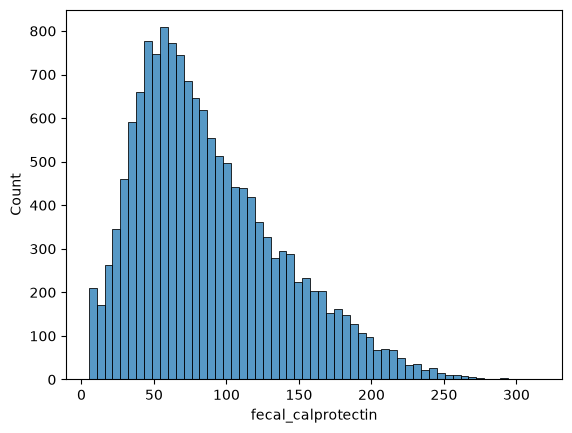

In [33]:
sns.histplot(df.fecal_calprotectin)

In [32]:
df.fecal_calprotectin

0        140.92
1         83.31
2        114.62
3         75.99
4        119.96
          ...  
14995    107.53
14996    137.75
14997     97.55
14998     16.22
14999    110.87
Name: fecal_calprotectin, Length: 15000, dtype: float64

In [34]:
map_crc_status = {'control':0, 'pre_cancerous':1, 'early_crc':2}

In [35]:
df.crc_status = df.crc_status.map(map_crc_status)

In [36]:
df.head()

,age,gender,bmi,crc_status,clinical_stage,cea,ca19_9,ca125,crp,il6,...,smoking_status,alcohol_use,previous_polyps,nsaid_use,statin_use,metformin_use,diabetes,hypertension,ibd,obesity
0,63,male,25.81,2,early_stage,7.98,31.16,48.16,10.56,6.69,...,never,NA,yes,no,no,no,yes,yes,no,no
1,49,female,33.40,1,pre_cancerous_lesion,2.14,30.90,24.99,6.23,2.95,...,never,NA,no,no,no,no,no,no,no,yes
2,71,female,29.48,2,early_stage,13.08,26.99,47.34,11.63,5.79,...,former,regular,no,yes,no,no,no,no,no,no
3,45,female,23.16,0,no_cancer,1.61,17.08,10.22,1.40,3.92,...,never,occasional,yes,no,no,no,no,no,no,no
4,49,male,21.34,1,pre_cancerous_lesion,4.99,20.24,20.13,6.47,5.84,...,never,regular,no,yes,no,no,no,yes,no,no


In [37]:
from sklearn.preprocessing import OrdinalEncoder

In [39]:
ordinal_enc = OrdinalEncoder(
    categories=[['no_cancer', 'pre_cancerous_lesion', 'early_stage']]
)

In [44]:
df['clinical_stage_encoded'] = ordinal_enc.fit_transform(df[['clinical_stage']]).astype(int)

In [45]:
df.head()

,age,gender,bmi,crc_status,clinical_stage,cea,ca19_9,ca125,crp,il6,...,alcohol_use,previous_polyps,nsaid_use,statin_use,metformin_use,diabetes,hypertension,ibd,obesity,clinical_stage_encoded
0,63,male,25.81,2,early_stage,7.98,31.16,48.16,10.56,6.69,...,NA,yes,no,no,no,yes,yes,no,no,2
1,49,female,33.40,1,pre_cancerous_lesion,2.14,30.90,24.99,6.23,2.95,...,NA,no,no,no,no,no,no,no,yes,1
2,71,female,29.48,2,early_stage,13.08,26.99,47.34,11.63,5.79,...,regular,no,yes,no,no,no,no,no,no,2
3,45,female,23.16,0,no_cancer,1.61,17.08,10.22,1.40,3.92,...,occasional,yes,no,no,no,no,no,no,no,0
4,49,male,21.34,1,pre_cancerous_lesion,4.99,20.24,20.13,6.47,5.84,...,regular,no,yes,no,no,no,yes,no,no,1


In [46]:
df['crc_status_encoded'] = df['crc_status']

In [47]:
df.head()

,age,gender,bmi,crc_status,clinical_stage,cea,ca19_9,ca125,crp,il6,...,previous_polyps,nsaid_use,statin_use,metformin_use,diabetes,hypertension,ibd,obesity,clinical_stage_encoded,crc_status_encoded
0,63,male,25.81,2,early_stage,7.98,31.16,48.16,10.56,6.69,...,yes,no,no,no,yes,yes,no,no,2,2
1,49,female,33.40,1,pre_cancerous_lesion,2.14,30.90,24.99,6.23,2.95,...,no,no,no,no,no,no,no,yes,1,1
2,71,female,29.48,2,early_stage,13.08,26.99,47.34,11.63,5.79,...,no,yes,no,no,no,no,no,no,2,2
3,45,female,23.16,0,no_cancer,1.61,17.08,10.22,1.40,3.92,...,yes,no,no,no,no,no,no,no,0,0
4,49,male,21.34,1,pre_cancerous_lesion,4.99,20.24,20.13,6.47,5.84,...,no,yes,no,no,no,yes,no,no,1,1


In [51]:
del df['clinical_stage']

In [52]:
df.head()

,age,gender,bmi,cea,ca19_9,ca125,crp,il6,tnf_alpha,fecal_calprotectin,...,previous_polyps,nsaid_use,statin_use,metformin_use,diabetes,hypertension,ibd,obesity,clinical_stage_encoded,crc_status_encoded
0,63,male,25.81,7.98,31.16,48.16,10.56,6.69,11.89,140.92,...,yes,no,no,no,yes,yes,no,no,2,2
1,49,female,33.40,2.14,30.90,24.99,6.23,2.95,6.43,83.31,...,no,no,no,no,no,no,no,yes,1,1
2,71,female,29.48,13.08,26.99,47.34,11.63,5.79,10.17,114.62,...,no,yes,no,no,no,no,no,no,2,2
3,45,female,23.16,1.61,17.08,10.22,1.40,3.92,4.65,75.99,...,yes,no,no,no,no,no,no,no,0,0
4,49,male,21.34,4.99,20.24,20.13,6.47,5.84,6.11,119.96,...,no,yes,no,no,no,yes,no,no,1,1


In [53]:
df = df.rename(columns={'clinical_stage_encoded': 'clinical_stage', 'crc_status_encoded': 'crc_status'})

In [54]:
df.head()

,age,gender,bmi,cea,ca19_9,ca125,crp,il6,tnf_alpha,fecal_calprotectin,...,previous_polyps,nsaid_use,statin_use,metformin_use,diabetes,hypertension,ibd,obesity,clinical_stage,crc_status
0,63,male,25.81,7.98,31.16,48.16,10.56,6.69,11.89,140.92,...,yes,no,no,no,yes,yes,no,no,2,2
1,49,female,33.40,2.14,30.90,24.99,6.23,2.95,6.43,83.31,...,no,no,no,no,no,no,no,yes,1,1
2,71,female,29.48,13.08,26.99,47.34,11.63,5.79,10.17,114.62,...,no,yes,no,no,no,no,no,no,2,2
3,45,female,23.16,1.61,17.08,10.22,1.40,3.92,4.65,75.99,...,yes,no,no,no,no,no,no,no,0,0
4,49,male,21.34,4.99,20.24,20.13,6.47,5.84,6.11,119.96,...,no,yes,no,no,no,yes,no,no,1,1
